# 3. Gradient Descent Variants

We continue with the network from last week and implement the three variants of gradient descent from the lecture: stochastic, batch and mini-batch GD.

## Setup
The following cells are the solution of last week's notebook. Just run them.

In [1]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
import pandas as pd

X, y = fetch_openml('mnist_784', version=1, return_X_y=True, data_home="./data", cache=True, parser='auto')
y_categorical = pd.get_dummies(y).astype('float32').values
X_scaled = (X/255).astype('float32').values
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_categorical, test_size=0.15, random_state=42)

In [2]:
import time
import numpy as np

class DeepNeuralNetwork():
    def __init__(self):
        
        # initialize weights randomly
        np.random.seed(0)
        self.w1 = np.random.randn(128, 784)
        self.w2 = np.random.randn(64, 128)
        self.w3 = np.random.randn(10, 64)

    def forward_pass(self, x_train):
        z1 = np.dot(self.w1, x_train)
        a1 = 1/(1 + np.exp(-z1)) # sigmoid activation
        z2 = np.dot(self.w2, a1)
        a2 = 1/(1 + np.exp(-z2)) # sigmoid activation
        z3 = np.dot(self.w3, a2)
        exps = np.exp(z3) 
        a3 = exps / exps.sum() # softmax activation
        
        # we need to remember all values for the gradient calculation
        self.fwdpass = [x_train, z1, a1, z2, a2, z3, a3]
        
        return a3
    
    
    def get_gradients(self, y, y_hat):
        # restore values from foward pass
        a0, z1, a1, z2, a2, z3, a3 = self.fwdpass
        
        # Calculate W3 update
        # for softmax + cross-entropy loss, the error at the output simplifies to y_hat - y
        error = y_hat - y
        gradient_w3 = np.outer(error, a2)

        # Calculate W2 update
        sigmoid_derivative = (np.exp(-z2))/((np.exp(-z2)+1)**2)
        error = np.dot(self.w3.T, error) * sigmoid_derivative
        gradient_w2 = np.outer(error, a1)

        # Calculate W1 update
        sigmoid_derivative = (np.exp(-z1))/((np.exp(-z1)+1)**2)
        error = np.dot(self.w2.T, error) * sigmoid_derivative
        gradient_w1 = np.outer(error, a0)

        return [gradient_w1, gradient_w2, gradient_w3]

In [3]:
def evaluate(dnn, X, y):
    predictions = []
    for x, y_true in zip(X, y):
        output = dnn.forward_pass(x)
        pred = np.argmax(output) # returns the index of the neuron with the highest value
        predictions.append(pred == np.argmax(y_true))
    return np.mean(predictions)

dnn = DeepNeuralNetwork()
print("Accuracy of the untrained network:", evaluate(dnn, X_test, y_test))

Accuracy of the untrained network: 0.10238095238095238


This is the training loop from last week (takes about 1 minute):

In [4]:
dnn = DeepNeuralNetwork()

no_epochs = 3
learning_rate = 0.01

start_time = time.time()
losses = []
for iteration in range(no_epochs):
    loss = 0
    for x,y in zip(X_train, y_train):
        y_hat = dnn.forward_pass(x)
        gradients = dnn.get_gradients(y, y_hat)
        
        loss += -np.log(np.dot(y, y_hat))
        
        # one step stochastic gradient descent
        dnn.w1 -= learning_rate * gradients[0]
        dnn.w2 -= learning_rate * gradients[1]
        dnn.w3 -= learning_rate * gradients[2]

    loss /= len(X_train) # average loss per sample
    print(f'Epoch: {iteration+1}, Time: {time.time() - start_time:.1f}s, Loss: {loss:.4f}')
    losses.append(loss)

Epoch: 1, Time: 14.4s, Loss: 0.6409
Epoch: 2, Time: 27.5s, Loss: 0.3351
Epoch: 3, Time: 40.8s, Loss: 0.2632


## Task 1: Stochastic gradient descent
The loop above does one update per data point, but always visits the data points in the same order. Change it to real SGD: visit the data points in a **random order** in every epoch.

In [12]:
dnn = DeepNeuralNetwork()

no_epochs = 3
learning_rate = 0.01

start_time = time.time()
losses_sgd = []
# your code goes here: the training loop from above, but visit the data points in a
# random order in every epoch (hint: np.random.permutation). Save the losses in losses_sgd.

for iteration in range(no_epochs):
    loss = 0
    perm = np.random.permutation(len(X_train))
    for i in perm:
        x_i, y_i = X_train[i], y_train[i]
        y_hat = dnn.forward_pass(x_i)
        gradients = dnn.get_gradients(y_i, y_hat)
        loss += -np.log(np.dot(y_i, y_hat))

        # one step stochastic gradient descent
        dnn.w1 -= learning_rate * gradients[0]
        dnn.w2 -= learning_rate * gradients[1]
        dnn.w3 -= learning_rate * gradients[2]

    loss /= len(X_train) # average loss per sample
    print(f'Epoch: {iteration+1}, Time: {time.time() - start_time:.1f}s, Loss: {loss:.4f}')
    losses_sgd.append(loss)

Epoch: 1, Time: 12.9s, Loss: 0.6531
Epoch: 2, Time: 36.1s, Loss: 0.3464
Epoch: 3, Time: 56.6s, Loss: 0.2759


## Task 2: Batch gradient descent
Do **one** weight update per epoch, using the mean gradient over **all** training data points.

*Check:* the losses should be 8.84, 5.67 and 4.87.

In [14]:
dnn = DeepNeuralNetwork()

no_epochs = 3
learning_rate = 1.0

start_time = time.time()
losses_batch = []
# your code goes here: in every epoch, sum up the gradients of ALL data points and do ONE
# weight update with the mean gradient. Save the losses in losses_batch.
for iteration in range(no_epochs):
    loss = 0
    # Summen-Gradienten für w1, w2, w3 auf 0 setzen
    grad_sum1 = np.zeros_like(dnn.w1)
    grad_sum2 = np.zeros_like(dnn.w2)
    grad_sum3 = np.zeros_like(dnn.w3)

    for x_i, y_i in zip(X_train, y_train):
        y_hat = dnn.forward_pass(x_i)
        gradients = dnn.get_gradients(y_i, y_hat)
        loss += -np.log(np.dot(y_i, y_hat))

        # Gradienten aufsummieren, KEIN Update hier
        grad_sum1 += gradients[0]
        grad_sum2 += gradients[1]
        grad_sum3 += gradients[2]

    # EIN Update mit dem mittleren Gradienten
    dnn.w1 -= grad_sum1/len(X_train)
    dnn.w2 -= grad_sum2/len(X_train)
    dnn.w3 -= grad_sum3/len(X_train)

    loss /= len(X_train) # average loss per sample
    print(f'Epoch: {iteration+1}, Time: {time.time() - start_time:.1f}s, Loss: {loss:.4f}')
    losses_batch.append(loss)

Epoch: 1, Time: 20.5s, Loss: 8.8435
Epoch: 2, Time: 34.2s, Loss: 5.6656
Epoch: 3, Time: 45.3s, Loss: 4.8663


## Task 3: Mini-batch gradient descent
Visit the data points in a random order and do one weight update per mini-batch of 64 data points, using the mean gradient of the mini-batch.

In [20]:
dnn = DeepNeuralNetwork()

no_epochs = 3
learning_rate = 0.5
batch_size = 64

start_time = time.time()
losses_mini = []
# your code goes here: in every epoch, visit the data points in a random order, split them into
# mini-batches of size batch_size and do one weight update per mini-batch with its mean gradient.
# Save the losses in losses_mini.
for iteration in range(no_epochs):
    loss = 0
    perm = np.random.permutation(len(X_train))

    for start in range(0, len(X_train), batch_size): # start, stop, step width is batch size, so 64
        batch_idx = perm[start:start+batch_size]

        # Summen für DIESEN Mini-Batch auf 0 setzen
        grad_sum1 = np.zeros_like(dnn.w1)
        grad_sum2 = np.zeros_like(dnn.w2)
        grad_sum3 = np.zeros_like(dnn.w3)

        for i in batch_idx:
            x_i, y_i = X_train[i], y_train[i]
            y_hat = dnn.forward_pass(x_i)
            gradients = dnn.get_gradients(y_i, y_hat)
            loss += -np.log(np.dot(y_i, y_hat))

            grad_sum1 += gradients[0]
            grad_sum2 += gradients[1]
            grad_sum3 += gradients[2]

        # ein Update pro Mini-Batch
        dnn.w1 -= learning_rate * grad_sum1 / len(batch_idx)
        dnn.w2 -= learning_rate * grad_sum2 / len(batch_idx)
        dnn.w3 -= learning_rate * grad_sum3 / len(batch_idx)

    loss /= len(X_train) # average loss per sample
    print(f'Epoch: {iteration+1}, Time: {time.time() - start_time:.1f}s, Loss: {loss:.4f}')
    losses_mini.append(loss)

Epoch: 1, Time: 12.8s, Loss: 0.7166
Epoch: 2, Time: 24.5s, Loss: 0.3732
Epoch: 3, Time: 35.8s, Loss: 0.2985


## Task 4: Compare

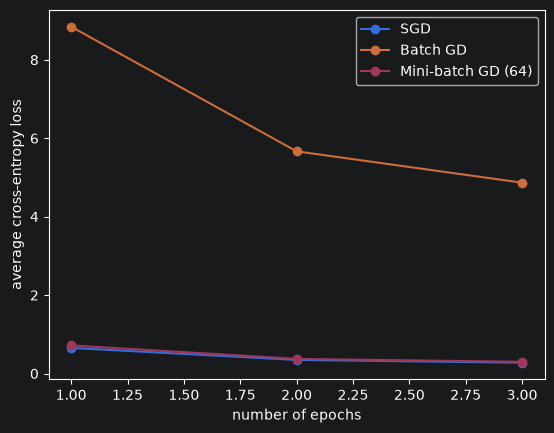

In [17]:
import matplotlib.pyplot as plt
for losses, name in [(losses_sgd, 'SGD'), (losses_batch, 'Batch GD'), (losses_mini, 'Mini-batch GD (64)')]:
    plt.plot(range(1, len(losses) + 1), losses, marker='o', label=name)
plt.xlabel('number of epochs')
plt.ylabel('average cross-entropy loss')
plt.legend()
plt.show()

1. All three variants compute the same number of gradients per epoch (one per data point). Why is batch GD so much worse after 3 epochs?
- Because there is only one singular weight update per epoch instead of one after every step. There is no real room to adjust.
2. Compare the time per epoch of the three variants. Why is it so similar?
- Because they all still parse the same dataset. The only difference is the method (gradient and pass forward are the costly functions that all run 3 times for every training)
3. **Bonus:** Run mini-batch GD with the learning rate of SGD (`learning_rate=0.01`). What happens? Why can mini-batch GD use a larger learning rate than SGD?
- Loss racks up pretty significantly. It can use a larger learning rate because it uses batches of data and thus, a bigger learning rate is better for less operations. It also CAN use a higher learning rate because the gradient is a mean over the training data per batch, which means it's not as vulnerable to statistical noise.